<a href="https://colab.research.google.com/github/eoinleen/Biophysics-general/blob/main/Dianthus_quadratic_only_v20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================================
# SETTINGS - edit these per experiment
# ============================================================================

# TOTAL target in the well (labelled + unlabelled), in nM. This is what the
# quadratic needs. It is NOT the dye concentration.
#   total = dye_in_well / labelled_fraction
#   e.g. K11 tracer: 10 nM dye / 0.64 = 15.6 nM;  K33: 10 / 0.56 = 17.7 nM
# One value per run, so analyse tracers with different totals in separate files.
TOTAL_TARGET_NM = 12.5
TRACER_DYE_NM   = 50.0      # reference only (reported, not used in the fit)

# Free-text descriptions used in the auto-generated methods paragraph.
TRACER_DESCRIPTION = ("His tagged binders "
                      "with NHS Red 2nd Generation dye")
TITRANT_NAME = "K11 DiUb"
X_LABEL = "[K11 DiUb] (nM)"

# Input layout (same as before): row 1 = sample names (one per column pair),
# row 2 = column headers, data below; columns alternate concentration (nM) / ratio.
# Column pairs that share a sample name are treated as repeats of that sample.
DATA_START_ROW = 2          # 0-based row index where numbers start

PLOT_NORMALISED = True    # False = raw 670/650 ratio; True = fraction bound (0-1),
                           #   each repeat scaled by its own fitted baselines
SHOW_RESIDUALS = False     # True = add residual panels under each fit

# Which fits count as determined (curve drawn, Kd reported) - same fit either way.
FIT_CRITERIA = "screen"    # "screen" = v17 rules, for initial screens:
                           #     R2 < SCREEN_MIN_R2 -> N.D.; R2 < SCREEN_APPROX_R2 or <50% bound
                           #     at top conc -> "Kd ~"; sorted R2 >= 0.75 by Kd, then the rest by R2
                           # "strict" = for anything beyond a screen:
                           #     N.D. if signal/noise < MIN_SIGNAL_TO_NOISE, or the 95% CI spans
                           #     more than MAX_CI_FOLD-fold, or the bootstrap failed
SCREEN_MIN_R2 = 0.5
SCREEN_APPROX_R2 = 0.88
MIN_SIGNAL_TO_NOISE = 5
MAX_CI_FOLD = 10
KD_LABEL = "plus_minus"    # "plus_minus" = v17 "Kd = x ± y" (y = half the 95% CI width)
                           # "ci" = "Kd = x (low–high)", exact when the CI is asymmetric
Y_DECIMALS = 2             # decimals on the ratio axis (v17: 2)
EXPORT_PPTX = True         # v17 PowerPoint figure: 3 x 6 panels per portrait slide
PPTX_FILENAME = "Figure_SpectralShift.pptx"
BAD_FIT_PLOT = "data_only" # "data_only" = points, no curve | "skip" = leave out of figures
                           # | "plot" = draw the curve anyway (still flagged N.D. in the table)

N_BOOTSTRAP = 500
RANDOM_SEED = 1
OUTPUT_DIR = "dianthus_results"

In [ ]:

# ============================================================================
# Dianthus spectral shift analysis v18
# ----------------------------------------------------------------------------
# One pre-specified model for every dataset: 1:1 binding with ligand depletion
# (Morrison quadratic). Repeats of a sample are fitted globally with a shared
# Kd and their own baselines. Alternative models are run only as diagnostics
# and never replace the reported Kd.
# ============================================================================

import os, shutil, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

T = float(TOTAL_TARGET_NM)
rng = np.random.default_rng(RANDOM_SEED)

# ----------------------------------------------------------------------------
# Models (concentrations in nM throughout; Kd fitted as log10 for conditioning)
# ----------------------------------------------------------------------------

def frac_bound(c, kd, t=T):
    """Morrison quadratic, written in the cancellation-free form
    f = 2c / (b + sqrt(b^2 - 4ct)),  b = c + t + kd  (identical algebraically)."""
    c = np.asarray(c, float)
    b = c + t + kd
    return 2 * c / (b + np.sqrt(np.maximum(b * b - 4 * c * t, 0)))


def frac_bound_hill(c, kd, n, t=T):
    """Diagnostic only: Hill binding with depletion, mass balance solved by
    bisection for free ligand (L_tot = L_free + t * theta(L_free))."""
    c = np.asarray(c, float)
    lo, hi = np.zeros_like(c), c.copy()
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        theta = 1 / (1 + (kd / np.maximum(mid, 1e-30)) ** n)
        over = mid + t * theta > c
        hi, lo = np.where(over, mid, hi), np.where(over, lo, mid)
    lf = 0.5 * (lo + hi)
    return 1 / (1 + (kd / np.maximum(lf, 1e-30)) ** n)


# Each model: shared params (after logKd) and per-repeat params.
MODELS = {
    "basic": dict(shared=[],    per=["R_unbound", "R_bound"]),
    "nonspecific": dict(shared=[], per=["R_unbound", "R_bound", "ns_slope"]),
    "hill": dict(shared=["n"],  per=["R_unbound", "R_bound"]),
}


def _predict(model, c, rep, p, n_rep):
    m = MODELS[model]
    kd = 10 ** p[0]
    ns, npr = len(m["shared"]), len(m["per"])
    per = p[1 + ns:].reshape(n_rep, npr)[rep]
    ru, rb = per[:, 0], per[:, 1]
    if model == "hill":
        f = frac_bound_hill(c, kd, p[1])
    else:
        f = frac_bound(c, kd)
    y = ru + f * (rb - ru)
    if model == "nonspecific":
        y = y + per[:, 2] * c
    return y


def global_fit(model, c, y, rep, n_rep, p0=None):
    """Fit all repeats of one sample at once. Returns params, residuals."""
    m = MODELS[model]
    cpos = c[c > 0]
    lo_kd, hi_kd = np.log10(cpos.min() / 100), np.log10(cpos.max() * 100)
    if p0 is None:
        # Baseline guesses from the lowest / highest concentrations of each repeat
        # (data are sorted, so order on the plate does not matter).
        per0 = []
        for r in range(n_rep):
            yr = y[rep == r]
            g = [np.mean(yr[:2]), np.mean(yr[-2:])]
            if model == "nonspecific":
                g.append(0.0)
            per0 += g
        shared0 = [1.0] if model == "hill" else []
        p0 = [np.log10(np.median(cpos))] + shared0 + per0
    lb = [lo_kd] + ([0.3] if model == "hill" else []) + [-np.inf] * (len(p0) - 1 - len(m["shared"]))
    ub = [hi_kd] + ([5.0] if model == "hill" else []) + [np.inf] * (len(p0) - 1 - len(m["shared"]))
    if model == "nonspecific":
        # Bound the slope so it cannot impersonate the binding transition:
        # at the top concentration it may contribute at most the full amplitude.
        amp = np.ptp(y)
        for r in range(n_rep):
            i = 1 + 3 * r + 2
            lb[i], ub[i] = -amp / cpos.max(), amp / cpos.max()
    p0 = np.clip(p0, np.array(lb) + 1e-9, np.array(ub) - 1e-9)
    f = lambda cc, *p: _predict(model, cc, rep, np.array(p), n_rep)
    p, _ = curve_fit(f, c, y, p0=p0, bounds=(lb, ub), maxfev=20000)
    return p, y - f(c, *p)


def aicc(rss, n, k):
    if n - k - 1 <= 0 or rss <= 0:
        return np.inf
    return n * np.log(rss / n) + 2 * k + 2 * k * (k + 1) / (n - k - 1)


def bootstrap_kd(c, y, rep, n_rep, p_hat, resid):
    """Residual bootstrap of the global basic fit. Residuals are resampled
    within each repeat, so each repeat keeps its own noise level."""
    fitted = y - resid
    kds = []
    for _ in range(N_BOOTSTRAP):
        yb = fitted.copy()
        for r in range(n_rep):
            idx = np.where(rep == r)[0]
            yb[idx] += rng.choice(resid[idx], idx.size, replace=True)
        try:
            pb, _ = global_fit("basic", c, yb, rep, n_rep, p0=p_hat)
            kds.append(10 ** pb[0])
        except Exception:
            pass
    kds = np.array(kds)
    if kds.size < 0.8 * N_BOOTSTRAP:
        return np.nan, np.nan, kds.size
    return *np.percentile(kds, [2.5, 97.5]), kds.size


# ----------------------------------------------------------------------------
# Loading
# ----------------------------------------------------------------------------

def load(path):
    raw = (pd.read_csv(path, header=None) if path.lower().endswith(".csv")
           else pd.read_excel(path, header=None))
    samples = {}
    for i in range(raw.shape[1] // 2):
        name = raw.iat[0, 2 * i]
        if pd.isna(name):
            name = raw.iat[0, 2 * i + 1]
        name = str(name).strip().strip('"\'') if pd.notna(name) else f"Sample {i+1}"
        c = pd.to_numeric(raw.iloc[DATA_START_ROW:, 2 * i], errors="coerce").to_numpy()
        y = pd.to_numeric(raw.iloc[DATA_START_ROW:, 2 * i + 1], errors="coerce").to_numpy()
        ok = np.isfinite(c) & np.isfinite(y) & (c >= 0)      # drop a row if EITHER is missing
        c, y = c[ok], y[ok]
        order = np.argsort(c)                                # plate order irrelevant
        samples.setdefault(name, []).append((c[order], y[order]))
    return samples


# ----------------------------------------------------------------------------
# Per-sample analysis
# ----------------------------------------------------------------------------

def analyse_sample(name, repeats):
    n_rep = len(repeats)
    c = np.concatenate([r[0] for r in repeats])
    y = np.concatenate([r[1] for r in repeats])
    rep = np.concatenate([np.full(len(r[0]), i) for i, r in enumerate(repeats)])

    out = dict(sample=name, n_repeats=n_rep, n_points=len(c), total_target_nM=T)

    p, resid = global_fit("basic", c, y, rep, n_rep)
    kd = 10 ** p[0]
    lo, hi, n_ok = bootstrap_kd(c, y, rep, n_rep, p, resid)
    out.update(Kd_nM=kd, Kd_CI95_low=lo, Kd_CI95_high=hi)

    # Each repeat on its own (same model): the spread is the honest error bar.
    kd_each = []
    for r in range(n_rep):
        try:
            pr, _ = global_fit("basic", c[rep == r], y[rep == r], np.zeros((rep == r).sum(), int), 1)
            kd_each.append(10 ** pr[0])
        except Exception:
            kd_each.append(np.nan)
    kd_each = np.array(kd_each)
    out["Kd_each_repeat_nM"] = "; ".join(f"{k:.3g}" for k in kd_each)
    if n_rep >= 2:
        out["Kd_repeats_mean_nM"] = np.nanmean(kd_each)
        out["Kd_repeats_SD_nM"] = np.nanstd(kd_each, ddof=1)

    # Quality numbers
    amp = np.abs(p[2::2] - p[1::2])                 # |R_bound - R_unbound| per repeat
    noise = np.std(resid, ddof=len(p))
    out["signal_to_noise"] = np.mean(amp) / noise if noise > 0 else np.inf
    out["frac_bound_at_top"] = float(frac_bound(c.max(), kd))
    # SS_tot about each repeat's own mean, so offsets between repeats cannot inflate R2
    ss_tot = sum(np.sum((y[rep == r] - y[rep == r].mean()) ** 2) for r in range(n_rep))
    out["R2"] = 1 - np.sum(resid ** 2) / ss_tot

    # Diagnostics: do other models fit clearly better?  (never change the Kd)
    a_basic = aicc(np.sum(resid ** 2), len(c), len(p))
    for alt in ("nonspecific", "hill"):
        try:
            pa, ra = global_fit(alt, c, y, rep, n_rep)
            out[f"dAICc_{alt}"] = a_basic - aicc(np.sum(ra ** 2), len(c), len(pa))
            if alt == "hill":
                out["hill_n"] = pa[1]
        except Exception:
            out[f"dAICc_{alt}"] = np.nan

    flags = []
    if kd < T / 2:
        flags.append(f"Kd below resolution limit (~{T/2:.3g} nM): reported as < upper 95% CL")
    if out["frac_bound_at_top"] < 0.8:
        flags.append(f"not saturated ({100*out['frac_bound_at_top']:.0f}% bound at top conc.)")
    if c.max() < 3 * kd:
        flags.append("top concentration < 3x Kd")
    if out["signal_to_noise"] < 5:
        flags.append("low signal/noise")
    if out.get("dAICc_nonspecific", 0) > 6:
        flags.append("non-specific term strongly favoured: inspect")
    if out.get("dAICc_hill", 0) > 6:
        flags.append(f"Hill strongly favoured (n={out.get('hill_n', np.nan):.2f}): inspect")
    if n_rep >= 2 and np.nanmax(kd_each) / np.nanmin(kd_each) > 3:
        flags.append("repeats disagree >3-fold")
    if np.isnan(lo):
        flags.append("bootstrap unstable")

    at_cap = kd > 0.99 * c.max() * 100               # ran into the upper Kd bound: no real fit
    if FIT_CRITERIA == "strict":
        bad = (at_cap or out["signal_to_noise"] < MIN_SIGNAL_TO_NOISE or np.isnan(lo)
               or hi / lo > MAX_CI_FOLD)
        approx = False
    else:                                            # v17 screen rules
        bad = at_cap or out["R2"] < SCREEN_MIN_R2
        approx = not bad and (out["R2"] < SCREEN_APPROX_R2 or out["frac_bound_at_top"] < 0.5)
    out["Kd_determined"] = not bad
    out["Kd_approx"] = approx
    if bad:
        flags.insert(0, "BAD FIT: Kd not determined")
    elif approx:
        flags.insert(0, "approximate Kd (screen criteria)")
    out["flags"] = " | ".join(flags) if flags else "none"

    plot_data = dict(c=c, y=y, rep=rep, p=p, resid=resid, kd=kd, n_rep=n_rep)
    return out, plot_data


# ----------------------------------------------------------------------------
# Plotting - v17 panel style
# ----------------------------------------------------------------------------

from io import BytesIO
from matplotlib.ticker import FuncFormatter, FormatStrFormatter, LogLocator, NullFormatter

plt.rcParams.update({"font.family": "DejaVu Sans", "svg.fonttype": "none", "pdf.fonttype": 42})
_SUP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")


def _v17_log_label(x, pos):                 # v17: plain numbers < 1000, then 10^n
    if x <= 0:
        return ""
    if x < 1000:
        return f"{int(x)}" if x >= 1 else f"{x:g}"
    e = int(round(np.log10(x)))
    m = x / 10 ** e
    sup = str(e).translate(_SUP)
    return f"10{sup}" if abs(m - 1) < 0.01 else f"{m:.0f}×10{sup}"


def _decades(a):
    """A labelled major tick at every decade, minor ticks between (v17 look)."""
    a.xaxis.set_major_locator(LogLocator(base=10, numticks=30))
    a.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=30))
    a.xaxis.set_major_formatter(FuncFormatter(_v17_log_label))
    a.xaxis.set_minor_formatter(NullFormatter())


def _kd_text(res):
    if not res["Kd_determined"]:
        return "Kd = N.D."
    if res["Kd_nM"] < T / 2:                 # below the resolution limit
        ub = res["Kd_CI95_high"] if np.isfinite(res["Kd_CI95_high"]) else T / 2
        return f"Kd < {ub:.1f} nM\nR² = {res['R2']:.3f}"
    kd, lo, hi = res["Kd_nM"], res["Kd_CI95_low"], res["Kd_CI95_high"]
    sym = "~" if res.get("Kd_approx") else "="
    if KD_LABEL == "ci" and np.isfinite(lo):
        s = f"Kd {sym} {kd:.1f} nM ({lo:.1f}–{hi:.1f})"
    elif np.isfinite(lo):                    # v17: half-width of the 95% CI
        s = f"Kd {sym} {kd:.1f} ± {(hi - lo) / 2:.1f} nM"
    else:
        s = f"Kd {sym} {kd:.1f} nM"
    return f"{s}\nR² = {res['R2']:.3f}"


def draw(ax, ax_res, name, d, res):
    c, y, rep, p, n_rep = d["c"], d["y"], d["rep"], d["p"], d["n_rep"]
    ru_r, rb_r = p[1::2], p[2::2]                     # per-repeat fitted baselines
    amp = rb_r - ru_r
    show_fit = res["Kd_determined"] or BAD_FIT_PLOT == "plot"
    norm = PLOT_NORMALISED and show_fit                # bad fit: always raw
    yy = (y - ru_r[rep]) / amp[rep] if norm else y
    pos = c > 0
    ax.scatter(c[pos], yy[pos], s=25, color="#8B0000", alpha=0.7, marker="x",
               linewidths=1, zorder=3)
    px, py = [c[pos]], [yy[pos]]                       # everything the label must avoid
    if show_fit:
        xs = np.logspace(np.log10(c[pos].min()), np.log10(c.max()), 200)
        fx = frac_bound(xs, d["kd"])
        curves = [fx] if norm else [ru_r[r] + fx * amp[r] for r in range(n_rep)]
        for cv in curves:
            ax.plot(xs, cv, color="black", linewidth=1.2, linestyle=(0, (3, 2)), zorder=2)
            px.append(xs); py.append(cv)
    ax.set_xscale("log")
    _decades(ax)
    ax.set_ylabel("Fraction bound" if norm else "Ratio", fontsize=7)
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f" if norm else f"%.{Y_DECIMALS}f"))
    if norm:
        ax.set_ylim(-0.1, 1.1)
    ax.set_title(name, fontsize=8, fontweight="bold", pad=3)
    ax.tick_params(labelsize=6, length=3, width=0.5, pad=2)
    ax.tick_params(which="minor", length=1.5, width=0.3)
    for sp in ax.spines.values():
        sp.set_linewidth(0.5)
    # v17 puts the box bottom-left; for rising curves bottom-right is the empty corner
    rising = norm or np.mean(amp) > 0
    label = ax.text(0.95 if rising else 0.05, 0.05, _kd_text(res), transform=ax.transAxes,
            fontsize=7, va="bottom", ha="right" if rising else "left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"))

    target = ax
    if ax_res is not None:
        ax_res.set_xscale("log")
        if show_fit:
            rr = d["resid"] / amp[rep] if norm else d["resid"]
            ax_res.scatter(c[pos], rr[pos], s=8, color="#8B0000", alpha=0.7, marker="x", linewidths=0.8)
            ax_res.axhline(0, color="0.5", lw=0.5)
        else:
            ax_res.text(0.5, 0.5, "no fit", transform=ax_res.transAxes,
                        ha="center", va="center", color="0.5", fontsize=6)
            ax_res.set_yticks([])
        ax_res.set_ylabel("Resid.", fontsize=6)
        _decades(ax_res)
        ax_res.tick_params(labelsize=5, length=2, width=0.5, pad=2)
        for sp in ax_res.spines.values():
            sp.set_linewidth(0.5)
        ax.tick_params(labelbottom=False)
        target = ax_res
    target.set_xlabel(X_LABEL, fontsize=7, labelpad=1, loc="left")
    return ax, label, np.concatenate(px), np.concatenate(py)


PANEL_W, PANEL_H = 2.4, 1.75                   # inches, v17 panel size


def _declutter(fig, drawn, max_iter=12):
    """Lower the y-axis floor until the Kd/R2 box overlaps no point and no curve."""
    for _ in range(max_iter):
        fig.canvas.draw()
        rend = fig.canvas.get_renderer()
        moved = False
        for ax, label, x, y in drawn:
            patch = label.get_bbox_patch()
            bb = (patch or label).get_window_extent(rend).expanded(1.04, 1.12)
            pts = ax.transData.transform(np.column_stack([x, y]))
            hit = ((pts[:, 0] >= bb.x0) & (pts[:, 0] <= bb.x1) &
                   (pts[:, 1] >= bb.y0) & (pts[:, 1] <= bb.y1))
            if hit.any():
                lo, hi = ax.get_ylim()
                ax.set_ylim(lo - 0.12 * (hi - lo), hi)
                moved = True
        if not moved:
            break
    for ax, *_ in drawn:                               # enough decimals that no two y labels repeat
        if ax.get_ylabel() != "Ratio":
            continue
        ticks = ax.get_yticks()
        step = np.min(np.diff(ticks)) if len(ticks) > 1 else 1
        dec = max(Y_DECIMALS, int(np.ceil(-np.log10(step) - 1e-9)))
        ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{dec}f"))


def _tiles(items, ncol, residuals):
    """Fixed 2.4 x 1.75 in tiles, no gaps between them, each laid out as its own
    small figure - the same geometry as the v17 PowerPoint panels."""
    nrow = int(np.ceil(len(items) / ncol))
    ph = PANEL_H + (0.5 if residuals else 0)
    fig = plt.figure(figsize=(PANEL_W * ncol, ph * nrow), layout="constrained")
    fig.get_layout_engine().set(w_pad=0.03, h_pad=0.03, wspace=0, hspace=0)
    subs = fig.subfigures(nrow, ncol, wspace=0, hspace=0, squeeze=False)
    drawn = []
    for i, (name, d, res) in enumerate(items):
        sf = subs[divmod(i, ncol)]
        if residuals:
            ax, axr = sf.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
        else:
            ax, axr = sf.subplots(), None
        drawn.append(draw(ax, axr, name, d, res))
    _declutter(fig, drawn)
    return fig


def _sorted(items):
    if FIT_CRITERIA == "strict":                     # determined Kds ascending, N.D. last
        return sorted(items, key=lambda it: (not it[2]["Kd_determined"], it[2]["Kd_nM"]))
    # v17: R2 >= 0.75 by Kd (tightest first), then the rest by R2 (worst last)
    def key(it):
        r = it[2]
        good = r["Kd_determined"] and r["R2"] >= 0.75
        return (0, r["Kd_nM"]) if good else (1, -r["R2"])
    return sorted(items, key=key)


def plot_sample(name, d, res, path):
    fig = _tiles([(name, d, res)], 1, SHOW_RESIDUALS)
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".svg")
    plt.close(fig)


def plot_grid(items, path, ncol=3):
    fig = _tiles(_sorted(items), ncol, SHOW_RESIDUALS)
    for ext in ("png", "svg", "pdf"):
        fig.savefig(f"{path}.{ext}", dpi=300)
    plt.show() if "ipykernel" in sys.modules else None
    plt.close(fig)


def export_pptx(items, path):
    """v17 layout: portrait 7.5 x 10.83 in slides, 3 x 6 panels of 2.4 x 1.75 in at 300 dpi.
    Panels are pictures; residual panels are never included here."""
    try:
        from pptx import Presentation
        from pptx.util import Inches
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "python-pptx", "-q"])
        from pptx import Presentation
        from pptx.util import Inches
    prs = Presentation()
    prs.slide_width, prs.slide_height = Inches(7.5), Inches(10.83)
    per_slide = 3 * 6
    items = _sorted(items)
    for s0 in range(0, len(items), per_slide):
        slide = prs.slides.add_slide(prs.slide_layouts[6])
        for i, item in enumerate(items[s0:s0 + per_slide]):
            r, col = divmod(i, 3)
            fig = _tiles([item], 1, residuals=False)
            buf = BytesIO()
            fig.savefig(buf, format="png", dpi=300)
            plt.close(fig)
            buf.seek(0)
            slide.shapes.add_picture(buf, Inches(0.15 + col * 2.4), Inches(0.05 + r * 1.78),
                                     width=Inches(PANEL_W), height=Inches(PANEL_H))
    prs.save(path)


# ----------------------------------------------------------------------------
# Methods text
# ----------------------------------------------------------------------------

def _criteria_sentence():
    if FIT_CRITERIA == "strict":
        return (f"Kd was reported as not determined (N.D.) when the signal-to-noise ratio "
                f"(mean amplitude / residual SD) was below {MIN_SIGNAL_TO_NOISE:g} or the 95% CI "
                f"spanned more than {MAX_CI_FOLD:g}-fold.")
    return (f"Kd was reported as not determined (N.D.) for fits with R² < {SCREEN_MIN_R2:g}, and "
            f"as approximate (~) for fits with R² < {SCREEN_APPROX_R2:g} or less than 50% bound "
            f"at the highest concentration.")


def _wrap(text, width=80):
    import textwrap
    out = []
    for para in text.split("\n\n"):
        if para.startswith("  "):                      # equation block: keep as is
            out.append(para)
        else:
            out.append(textwrap.fill(" ".join(para.split()), width))
    return "\n\n".join(out) + "\n"


def methods_text(table=None):
    multi = table is not None and len(table) and table["n_repeats"].max() > 1
    pm = ("half the width of the 95% confidence interval" if KD_LABEL == "plus_minus"
          else None)
    if multi:
        reps = ("Independent repeats were fitted globally with a shared Kd and repeat-specific "
                "R_unbound and R_bound. ")
        boot = "residuals resampled within each repeat"
        each = (" Each repeat was also fitted separately, and the mean +/- SD of these Kd "
                "values is reported.")
    else:
        reps = "Replicate measurements of each sample were pooled into a single fit. "
        boot = "residuals resampled with replacement"
        each = ""
    return _wrap(f"""Data analysis. For each sample, the 670/650 nm emission ratio (R) was fitted
as a function of total {TITRANT_NAME} concentration (C) to a 1:1 binding model
that accounts for ligand depletion (Morrison quadratic):

  R = R_unbound + (R_bound - R_unbound) * f,
  f = [(C + T + Kd) - sqrt((C + T + Kd)^2 - 4*C*T)] / (2*T)

where T is the total concentration of tracer ({TRACER_DESCRIPTION}), labelled plus
unlabelled ({T:g} nM in the well; {TRACER_DYE_NM:g} nM dye). {reps}Fitting used
non-linear least squares (SciPy curve_fit), with Kd fitted on a log10 scale and
constrained to between 1/100 of the lowest and 100x the highest non-zero
concentration; tracer-only (0 nM) wells were included. Fits reaching the upper
Kd limit were reported as not determined. The 95% confidence interval for Kd was
obtained by residual bootstrap ({N_BOOTSTRAP} resamples, {boot};
2.5th-97.5th percentiles).{each}{" Values given as Kd +/- x report x as " + pm + "." if pm else ""}
R2 was calculated as 1 - SS_res/SS_tot, with SS_tot taken about the mean of each
repeat. Because the
midpoint of the curve lies at Kd + T/2, Kd values below T/2 ({T/2:.3g} nM) are not
resolved and are reported as upper bounds, given by the upper 95% confidence limit.
{_criteria_sentence()} Models including a linear non-specific term or a Hill
coefficient were compared with the 1:1 model by AICc as diagnostics only.
""")


# ----------------------------------------------------------------------------
# Run
# ----------------------------------------------------------------------------

def run(path):
    if os.path.isdir(OUTPUT_DIR):
        shutil.rmtree(OUTPUT_DIR)
    os.makedirs(OUTPUT_DIR)
    samples = load(path)
    print(f"Total target in well: {T:g} nM  (dye {TRACER_DYE_NM:g} nM)  |  "
          f"resolution limit Kd ~ {T/2:.3g} nM\n")
    rows, items = [], []
    for name, reps in samples.items():
        try:
            res, d = analyse_sample(name, reps)
        except Exception as e:
            print(f"{name}: fit failed ({e})")
            continue
        rows.append(res)
        if not res["Kd_determined"] and BAD_FIT_PLOT == "skip":
            print(f"{name}: bad fit, left out of figures")
            continue
        items.append((name, d, res))
        safe = "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in name)
        plot_sample(name, d, res, os.path.join(OUTPUT_DIR, safe))
    table = pd.DataFrame(rows)
    # Human-readable Kd column: N.D. for bad fits (numbers kept in Kd_nM for inspection)
    table.insert(3, "Kd_reported", [
        (f"< {(r['Kd_CI95_high'] if np.isfinite(r['Kd_CI95_high']) else T / 2):.3g}"
         if r["Kd_nM"] < T / 2 else ("~ " if r["Kd_approx"] else "") + f"{r['Kd_nM']:.3g}")
        if r["Kd_determined"] else "N.D."
        for _, r in table.iterrows()])
    table.to_csv(os.path.join(OUTPUT_DIR, "results.csv"), index=False)
    if items:
        plot_grid(items, os.path.join(OUTPUT_DIR, "all_samples"))
        if EXPORT_PPTX:
            export_pptx(items, os.path.join(OUTPUT_DIR, PPTX_FILENAME))
    with open(os.path.join(OUTPUT_DIR, "methods.txt"), "w") as fh:
        fh.write(methods_text(table))

    show = ["sample", "n_repeats", "Kd_reported", "Kd_CI95_low", "Kd_CI95_high",
            "Kd_repeats_mean_nM", "Kd_repeats_SD_nM", "frac_bound_at_top", "flags"]
    with pd.option_context("display.max_colwidth", 80, "display.width", 200,
                           "display.float_format", "{:.3g}".format):
        print(table[[s for s in show if s in table.columns]].to_string(index=False))
    print("\n" + methods_text(table))
    shutil.make_archive(OUTPUT_DIR, "zip", OUTPUT_DIR)
    return table

Saving 20260114-fitting-Dianthus_EL_names.xlsx to 20260114-fitting-Dianthus_EL_names (13).xlsx
Total target in well: 12.5 nM  (dye 50 nM)  |  resolution limit Kd ~ 6.25 nM



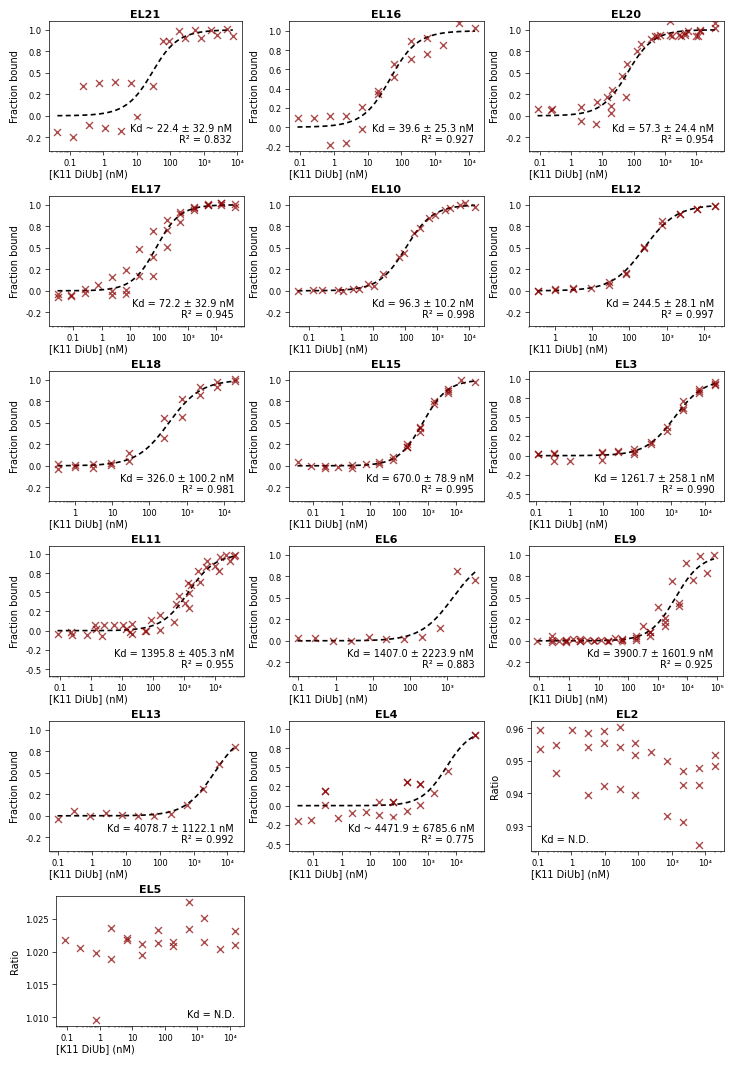

sample  n_repeats Kd_reported  Kd_CI95_low  Kd_CI95_high  frac_bound_at_top                                                                             flags
  EL15          1         670          593           751              0.985                                                                              none
  EL17          1        72.2         45.8           112              0.998                                                                              none
   EL9          1     3.9e+03     2.64e+03      5.85e+03              0.953                                                                              none
  EL20          1        57.3         38.8          87.5              0.999                                                                              none
  EL11          1     1.4e+03     1.04e+03      1.85e+03               0.97                                                                              none
  EL13          1    4.08e+03     3.23e+03      5.48

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Upload the Excel/CSV file (Colab) or set PATH to a local file, then run.
PATH = None   # e.g. "my_plate.xlsx" when running locally

try:
    from google.colab import files
    up = files.upload()
    PATH = list(up.keys())[0]
except ImportError:
    pass

results = run(PATH)

try:
    files.download(OUTPUT_DIR + ".zip")
except NameError:
    print(f"Outputs in {OUTPUT_DIR}/ and {OUTPUT_DIR}.zip")